In [1]:
# Zachary Katz
# zachary_katz@mines.edu
# 11 November 2026

"""
Programatically download n tracks of SWOT L3_LR_SSH_Expert data for all available
cycles, clean, and calculate tides in an harmonic inversion.
"""

# Imports
import altimetry_downloader_aviso
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import xarray as xr
import matplotlib.pyplot as plt
from cartopy import crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from utide import solve
import matplotlib.dates as mdates
from joblib import Parallel, delayed
import time
import pyTMD
import os


Plotting N2


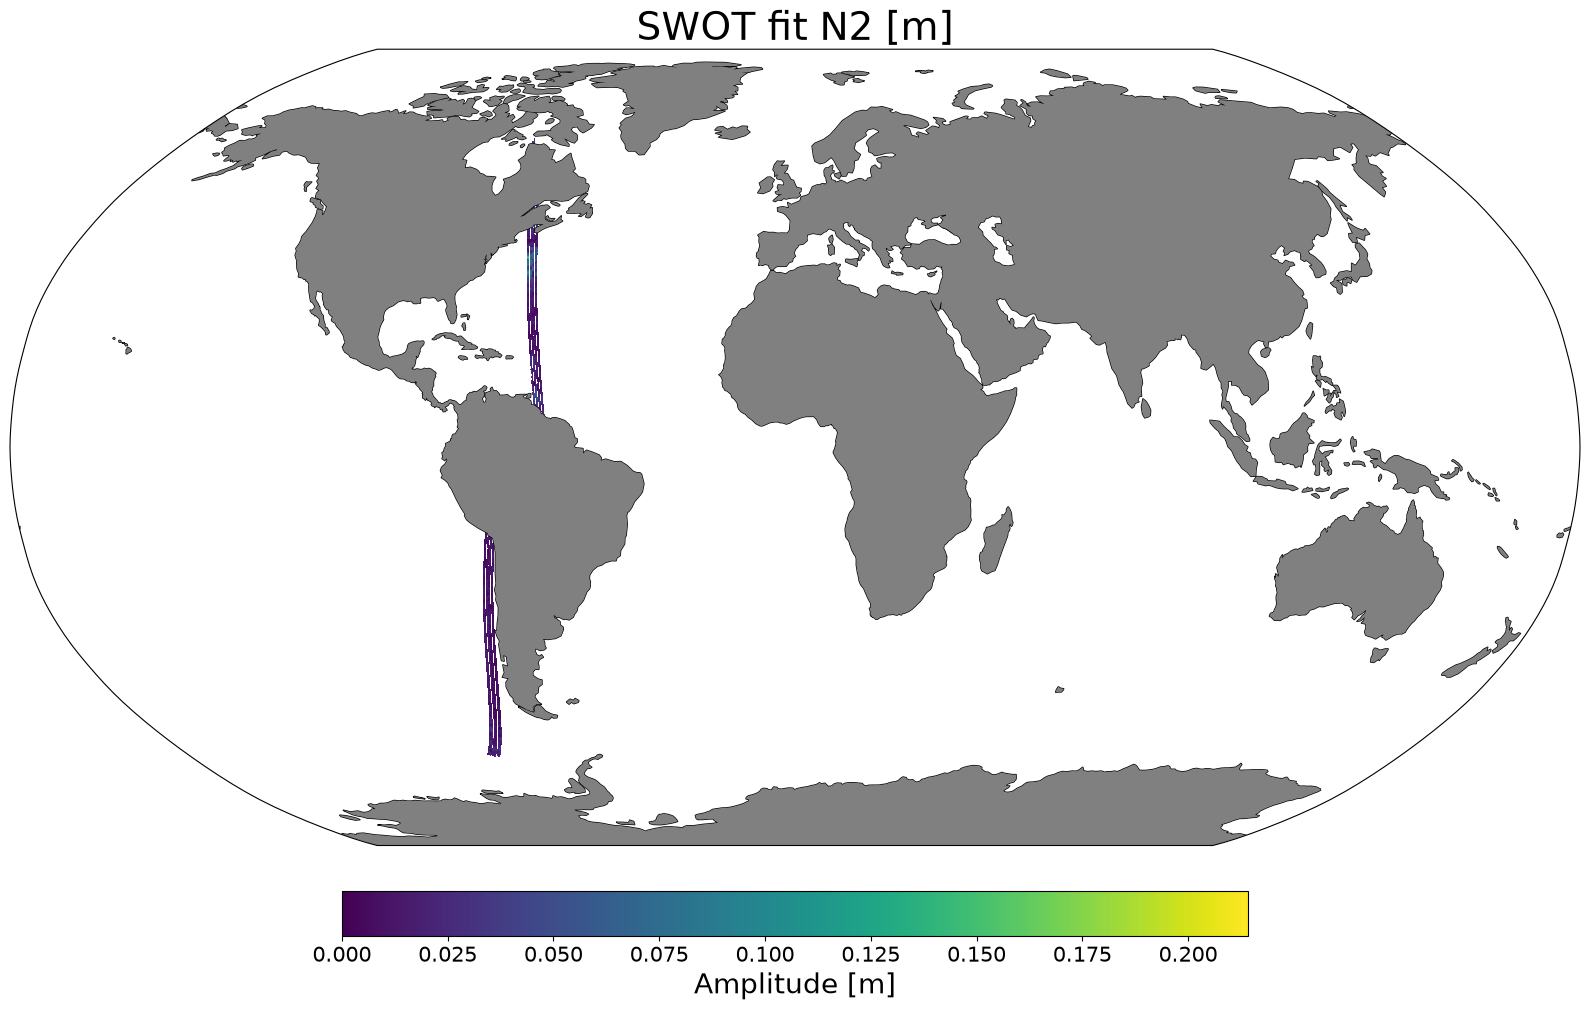

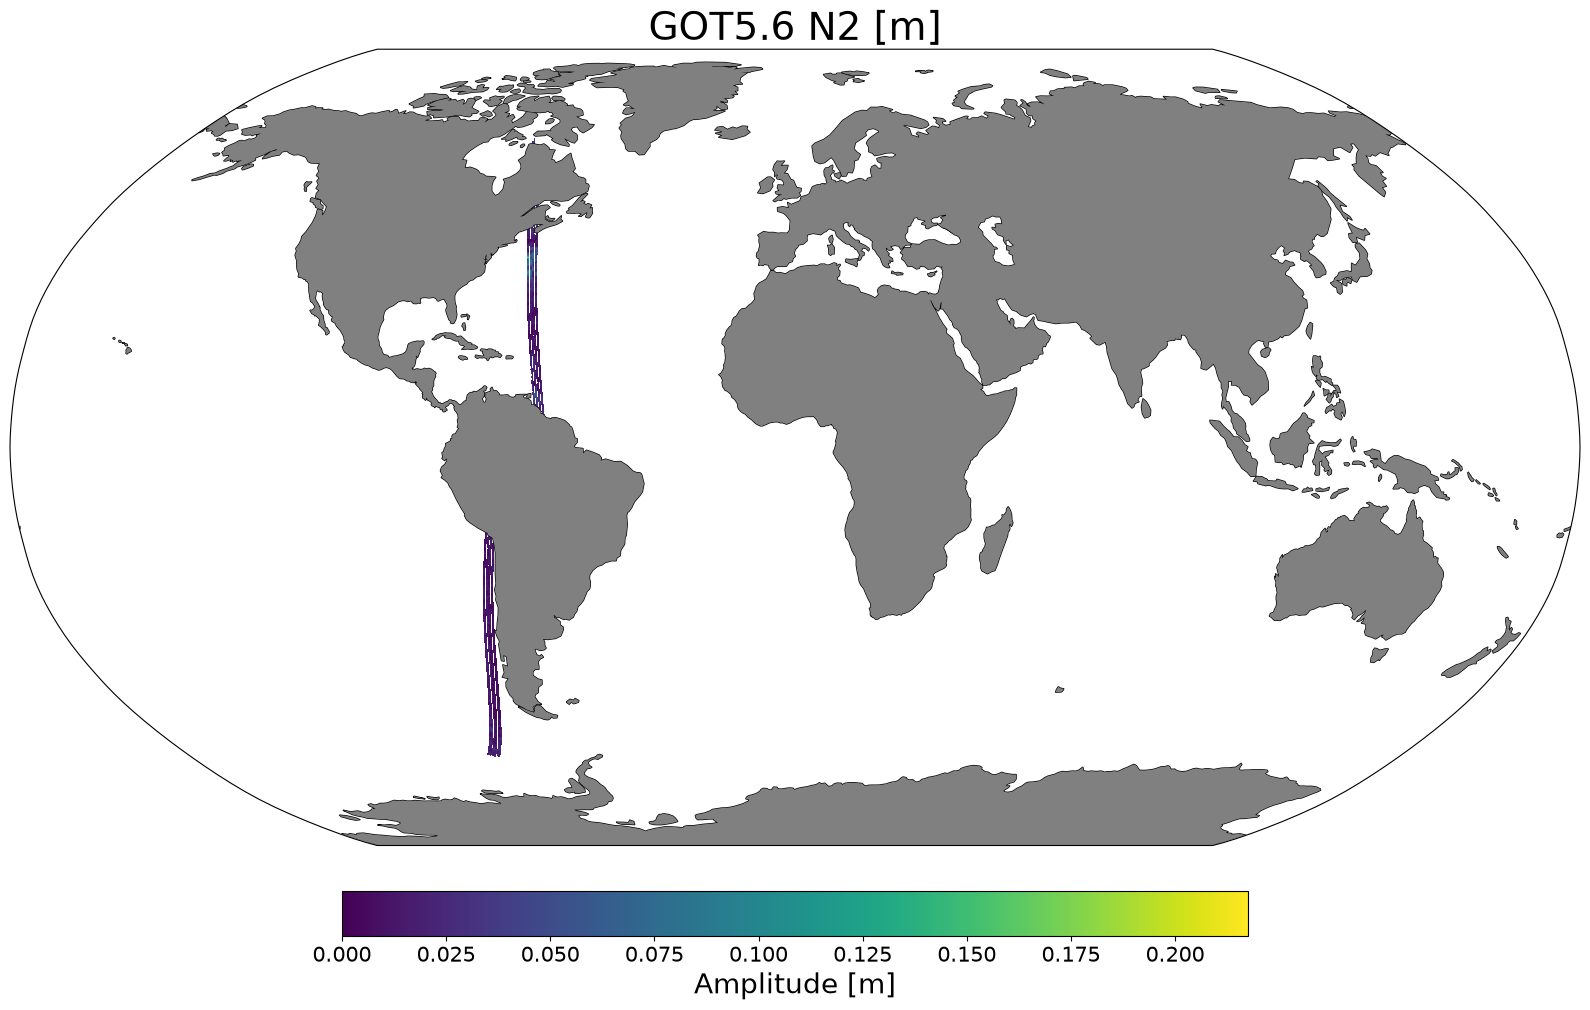

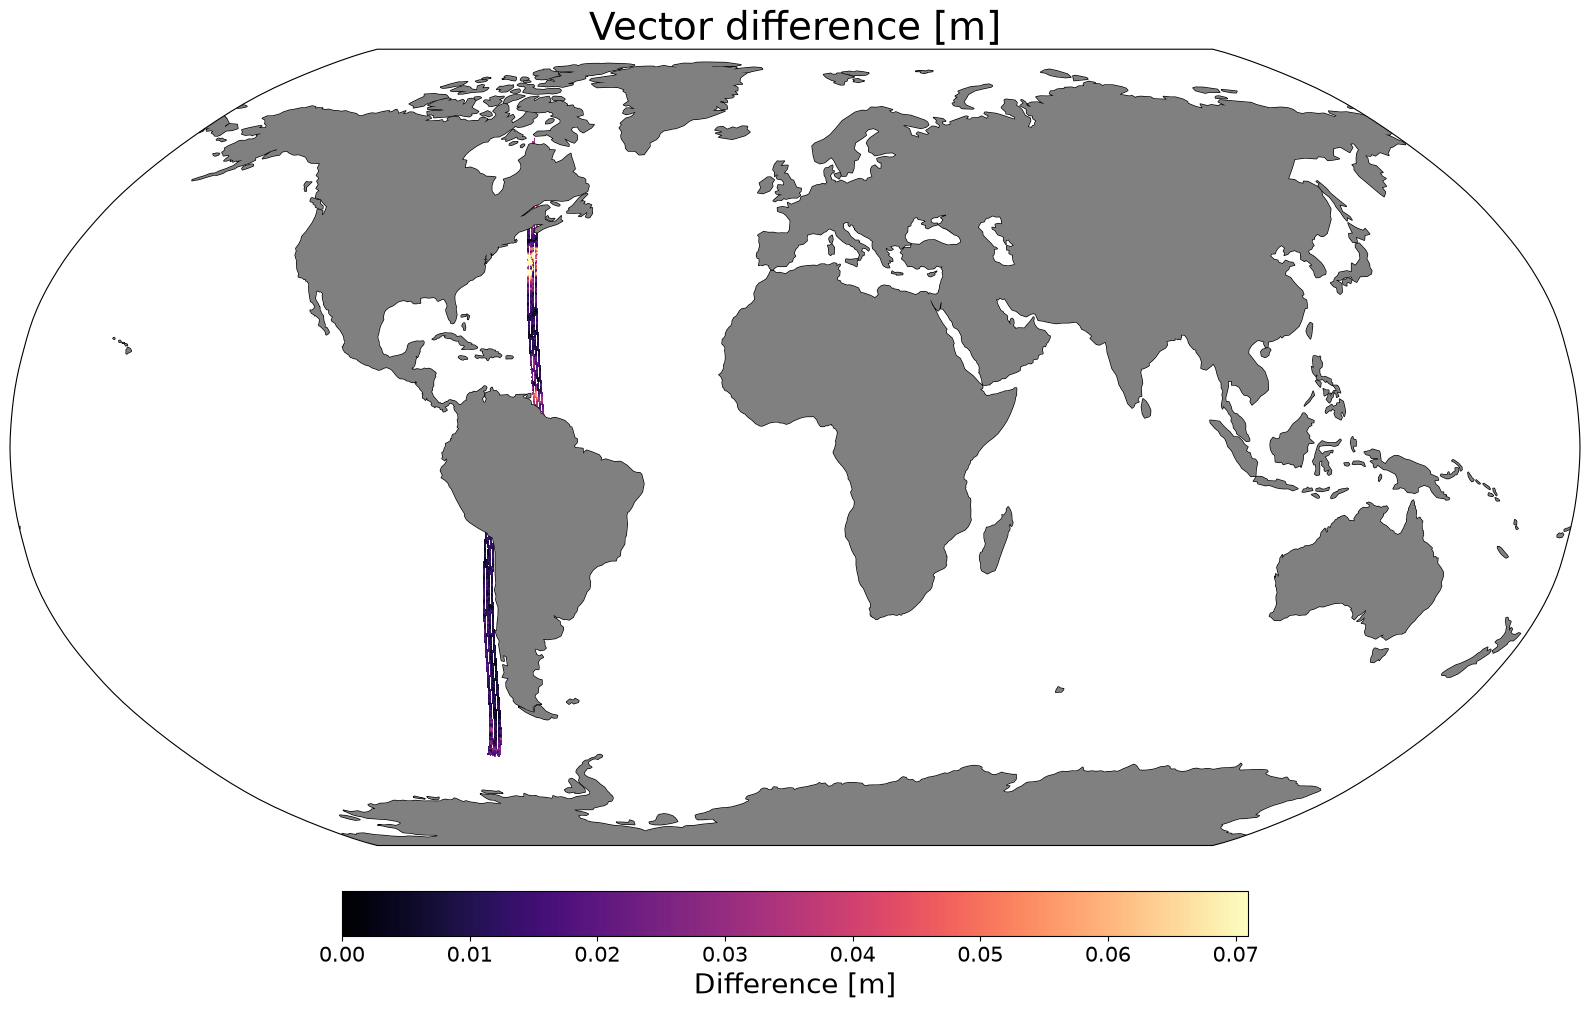

In [28]:
projection = "spilhaus"
projection = "robinson"

constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
for constituent in constits[2:3]:
    print(f"Plotting {constituent}")
    k = constits.index(constituent)
    files = sorted(Path("./_Data").glob("swot_tide_fit_pass_*.nc"))
    percentiles = [[] for _ in range(3)]
    # Calculate 98th percentile for each variable across all passes
    for path in files:
        with xr.open_dataset(path) as ds:
            for i, var in enumerate(["amplitude", "amp_got", "vec"]):
                v = ds[var].isel(constituent=k).values
                percentiles[i].append(v[np.isfinite(v)])
    limits = [(0, np.nanpercentile(np.concatenate(v), 98)) for v in percentiles]

    if projection == "spilhaus":
        fig_swot, ax_swot = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
        fig_got, ax_got = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
        fig_vec, ax_vec = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Spilhaus()})
    elif projection == "robinson":
        fig_swot, ax_swot = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
        fig_got, ax_got = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
        fig_vec, ax_vec = plt.subplots(1, 1, figsize=(16, 10), subplot_kw={"projection": ccrs.Robinson()})
    titles = [f"SWOT fit {constituent} [m]",f"GOT5.6 {constituent} [m]","Vector difference [m]"]
    cmaps = ["viridis", "viridis", "magma"]
    save_name = ['SWOT', 'GOT', 'Difference']

    for fig, ax, ttl, cm, lim, svnm in zip([fig_swot, fig_got, fig_vec], [ax_swot, ax_got, ax_vec], titles, cmaps, limits, save_name):
        for path in files:
            with xr.open_dataset(path) as ds:
                lon = ds["longitude"].values
                lat = ds["latitude"].values

                variables = [
                    ds["amplitude"].isel(constituent=k).values,
                    ds["amp_got"].isel(constituent=k).values,
                    ds["vec"].isel(constituent=k).values
                ]
                
                for i, v in enumerate(variables):
                    valid = (
                        np.isfinite(v)
                        & np.isfinite(lon)
                        & np.isfinite(lat)
                    )
                    v = np.where(valid, v, np.nan)
                    variables[i] = v


                    sc = ax.pcolormesh(
                        lon,
                        lat,
                        v,
                        cmap=cm,
                        vmin=lim[0],
                        vmax=lim[1],
                        shading="auto",
                        transform=ccrs.PlateCarree(),
                        rasterized=True
                    )

        ax.coastlines()
        ax.add_feature(
            cfeature.LAND,
            facecolor="gray",
            edgecolor="none",
            zorder=2
        )
        ax.set_title(ttl, fontsize=28)
        sm = plt.cm.ScalarMappable(
            norm=plt.Normalize(*lim),
            cmap=cm
        )
        cbar = plt.colorbar(
            sm,
            ax=ax,
            orientation="horizontal",
            pad=0.05,
            fraction=0.05
        )
        cbar.ax.tick_params(labelsize=15)
        cbar.set_label(
            "Amplitude [m]" if ttl != titles[2] else "Difference [m]",
            fontsize=20,
        )

        if projection == "spilhaus":
            ax.set_global()
        elif projection == "robinson":
            ax.set_global()

        fig.tight_layout()
        fig.savefig(f"./swot_tide_fit_{constituent}_{svnm}.png", dpi=300)

In [17]:
import numpy as np
import cartopy.crs as ccrs

def get_spilhaus_mask(lon2d, lat2d, projection):
    # Transform geographic coordinates into Spilhaus coordinates
    xy = projection.transform_points(
        ccrs.PlateCarree(), lon2d, lat2d
    )
    x = xy[..., 0]
    y = xy[..., 1]

    bound = np.mean(np.abs(np.asarray(projection.bounds)))

    # Identify points near the projection boundary
    near_bound = (
        (np.abs(x) > 0.95 * bound) |
        (np.abs(y) > 0.95 * bound)
    )

    # Rotate coordinates to align with the projection boundary
    theta = np.deg2rad(45)
    rot_x = x * np.cos(theta) - y * np.sin(theta)
    rot_y = y * np.cos(theta) + x * np.sin(theta)

    # Detect sign changes across cell diagonals
    change_sign0 = (
        (rot_x[1:, 1:] * rot_x[:-1, :-1] < 0) |
        (rot_y[1:, 1:] * rot_y[:-1, :-1] < 0)
    )

    change_sign1 = (
        (rot_x[1:, :-1] * rot_x[:-1, 1:] < 0) |
        (rot_y[1:, :-1] * rot_y[:-1, 1:] < 0)
    )

    change_sign = change_sign0 | change_sign1

    # Expand the mask to all four corners of affected cells
    sign_change = np.zeros_like(x, dtype=bool)

    sign_change[1:, 1:] |= change_sign
    sign_change[:-1, :-1] |= change_sign
    sign_change[1:, :-1] |= change_sign
    sign_change[:-1, 1:] |= change_sign

    return near_bound & sign_change


Plotting M2


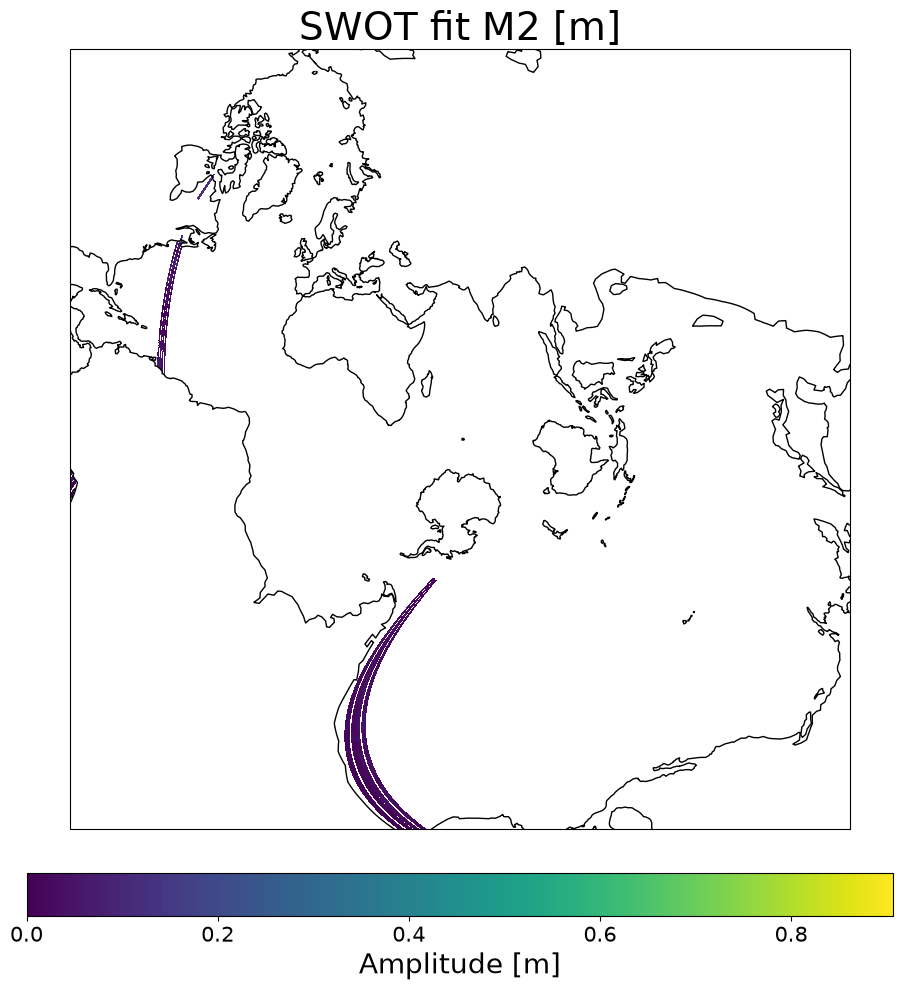

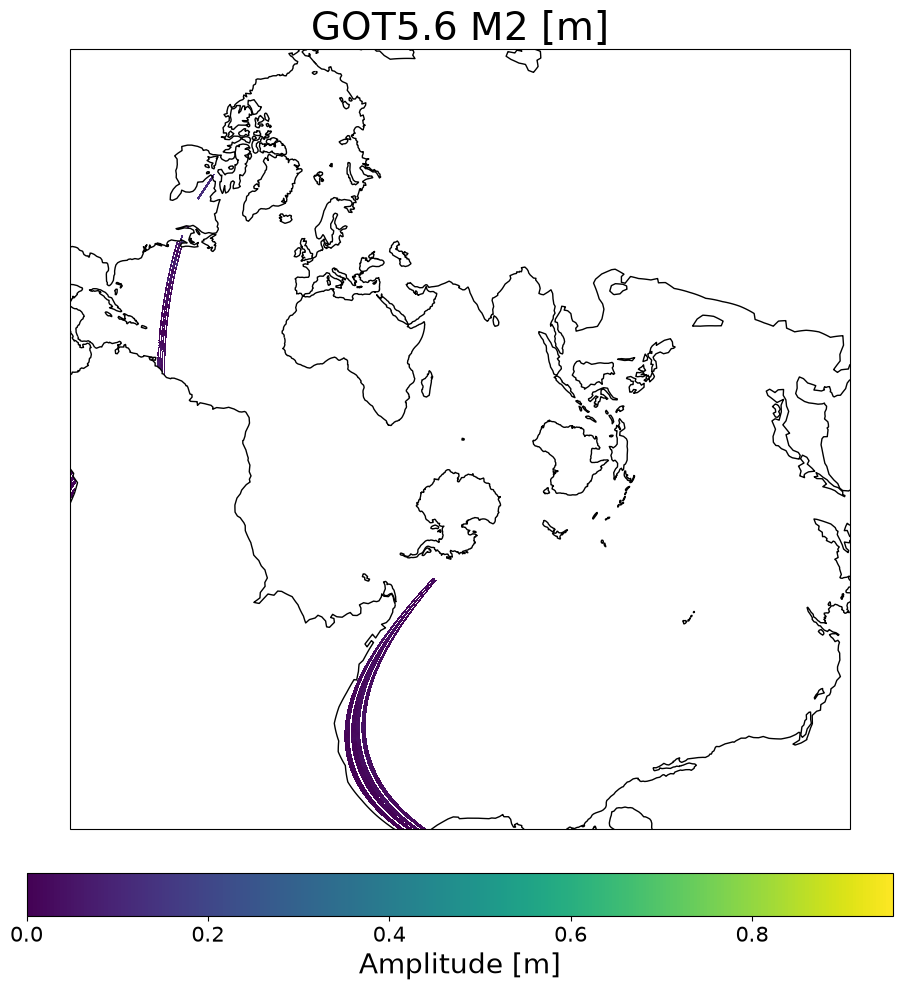

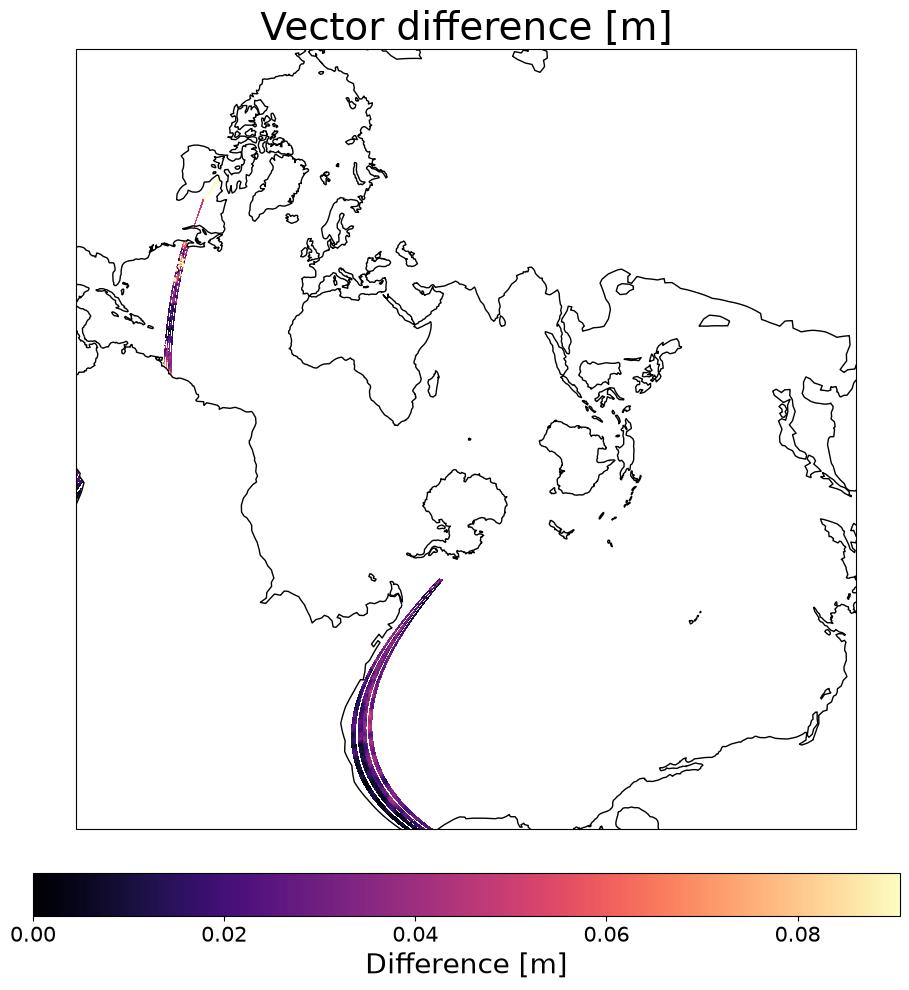

In [29]:
projection = "spilhaus"
#projection = "robinson"

constits = ["M2", "S2", "N2", "K2", "K1", "O1", "P1", "Q1"]
for constituent in constits[:1]:
    print(f"Plotting {constituent}")
    k = constits.index(constituent)
    files = sorted(Path("./_Data").glob("swot_tide_fit_pass_*.nc"))
    percentiles = [[] for _ in range(3)]
    # Calculate 98th percentile for each variable across all passes
    for path in files:
        with xr.open_dataset(path) as ds:
            for i, var in enumerate(["amplitude", "amp_got", "vec"]):
                v = ds[var].isel(constituent=k).values
                percentiles[i].append(v[np.isfinite(v)])
    limits = [(0, np.nanpercentile(np.concatenate(v), 98)) for v in percentiles]

    if projection == "spilhaus":
        fig_swot, ax_swot = plt.subplots(1, 1, figsize=(10, 10), subplot_kw={"projection": ccrs.Spilhaus()})
        fig_got, ax_got = plt.subplots(1, 1, figsize=(10, 10), subplot_kw={"projection": ccrs.Spilhaus()})
        fig_vec, ax_vec = plt.subplots(1, 1, figsize=(10, 10), subplot_kw={"projection": ccrs.Spilhaus()})
    elif projection == "robinson":
        fig_swot, ax_swot = plt.subplots(1, 1, figsize=(10, 10), subplot_kw={"projection": ccrs.Robinson()})
        fig_got, ax_got = plt.subplots(1, 1, figsize=(10, 10), subplot_kw={"projection": ccrs.Robinson()})
        fig_vec, ax_vec = plt.subplots(1, 1, figsize=(10, 10), subplot_kw={"projection": ccrs.Robinson()})
    titles = [f"SWOT fit {constituent} [m]",f"GOT5.6 {constituent} [m]","Vector difference [m]"]
    cmaps = ["viridis", "viridis", "magma"]
    save_name = ['SWOT', 'GOT', 'Difference']

    for fig, ax, ttl, cm, lim, svnm in zip([fig_swot, fig_got, fig_vec], [ax_swot, ax_got, ax_vec], titles, cmaps, limits, save_name):
        for path in files:
            with xr.open_dataset(path) as ds:
                lon = ds["longitude"].values
                lat = ds["latitude"].values

                variables = [
                    ds["amplitude"].isel(constituent=k).values,
                    ds["amp_got"].isel(constituent=k).values,
                    ds["vec"].isel(constituent=k).values
                ]
                
                mask = get_spilhaus_mask(lon, lat, ccrs.Spilhaus())
                for i, v in enumerate(variables):
                    valid = (
                        np.isfinite(v)
                        & np.isfinite(lon)
                        & np.isfinite(lat)
                    )
                    v = np.where(valid, v, np.nan)
                    variables[i] = v

                    v_plot = np.ma.masked_where(mask, v)
                    sc = ax.pcolormesh(
                        lon,
                        lat,
                        v_plot,
                        cmap=cm,
                        vmin=lim[0],
                        vmax=lim[1],
                        shading="auto",
                        transform=ccrs.PlateCarree(),
                        rasterized=True
                    )

        ax.coastlines()
        ax.set_title(ttl, fontsize=28)
        sm = plt.cm.ScalarMappable(
            norm=plt.Normalize(*lim),
            cmap=cm
        )
        cbar = plt.colorbar(
            sm,
            ax=ax,
            orientation="horizontal",
            pad=0.05,
            fraction=0.05
        )
        cbar.ax.tick_params(labelsize=15)
        cbar.set_label(
            "Amplitude [m]" if ttl != titles[2] else "Difference [m]",
            fontsize=20,
        )

        if projection == "spilhaus":
            ax.set_global()
        elif projection == "robinson":
            ax.set_global()


        fig.tight_layout()
        fig.savefig(f"./swot_tide_fit_{constituent}_{svnm}.png", dpi=300)

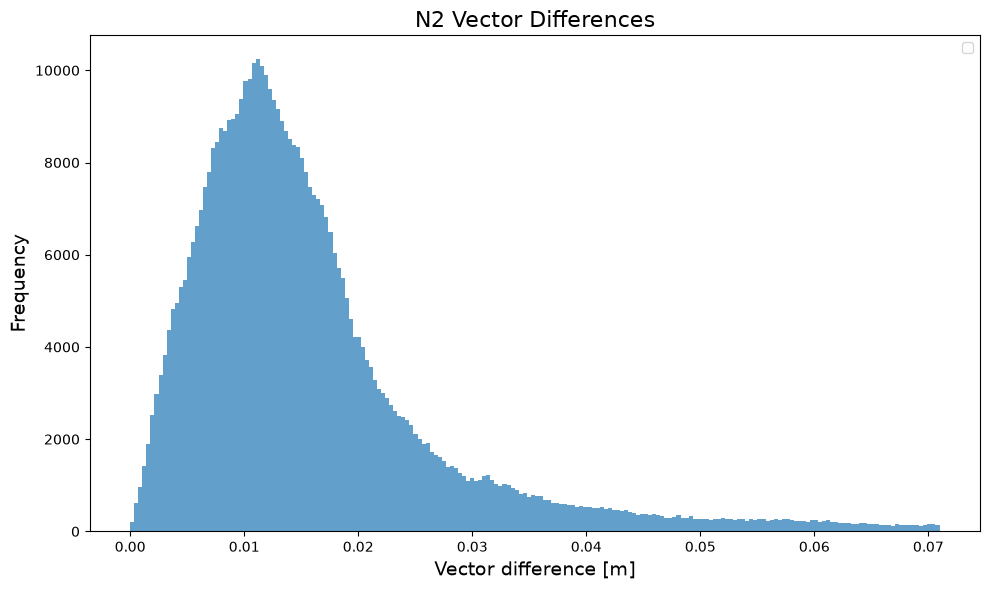

In [ ]:
# Histogram of differences
for constituent in constits[2:3]:
    k = constits.index(constituent)
    files = sorted(Path("./_Data").glob("swot_tide_fit_pass_*.nc"))
    percentiles = [[] for _ in range(3)]
    # Calculate 98th percentile for each variable across all passes
    for path in files:
        with xr.open_dataset(path) as ds:
            v = ds["vec"].isel(constituent=k).values
            percentiles[2].append(v[np.isfinite(v)])
    limits = [(0, np.nanpercentile(np.concatenate(percentiles[2]), 98))]

    fig_hist, ax_hist = plt.subplots(1, 1, figsize=(10, 6))
    all_values = []

    for path in files:
        with xr.open_dataset(path) as ds:
            v = ds["vec"].isel(constituent=k).values
            v = v[np.isfinite(v)]
            all_values.append(v)

    all_values = np.concatenate(all_values)

    ax_hist.hist(
        all_values,
        bins=200,
        range=limits[0],
        alpha=0.7,
    )
    ax_hist.set_xlabel("Vector difference [m]", fontsize=14)
    ax_hist.set_ylabel("Frequency", fontsize=14)
    ax_hist.set_title(f"{constituent} Vector Differences", fontsize=16)
    ax_hist.legend(fontsize=10)
    fig_hist.tight_layout()
    fig_hist.savefig(f"./swot_tide_fit_{constituent}_histogram.png", dpi=300)